# Иерархический кластерный анализ

---

**Выполнил:** Романов Данил Павлович

**Группа:** М4181

---

In [261]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from sklearn.metrics import silhouette_score, adjusted_rand_score

Загрузим датасет **Economics of Cities**

Параметры:
- `sep=";"` - разделение между признаками в файле
- `decimal=","` - вещественные числа записаны через запятую, а не точку

In [262]:
df = pd.read_csv("Задачи для лабораторной 1-3/задача_2_Economics of Cities/Econom_Cities_data.csv", sep=";", decimal=",")
df.shape

(48, 4)

In [263]:
df.head()

,City,Work,Price,Salary
0,Amsterdam,1714,65.6,49.0
1,Athens,1792,53.8,30.4
2,Bogota,2152,37.9,11.5
3,Bombay,2052,30.3,5.3
4,Brussels,1708,73.8,50.5


Сразу видно, что признаки находятся в разных масштабах - данные **нужно будет стандартизовать**. Посмотрим на функцию `describe`

In [264]:
df.describe()

,Work,Price,Salary
count,48.000000,48.000000,48.000000
mean,1384.958333,68.860417,-378.727083
std,2404.897007,21.784659,2027.338052
min,-9999.000000,30.300000,-9999.000000
25%,1740.750000,49.650000,12.250000
50%,1834.500000,70.500000,40.300000
75%,1972.750000,81.700000,58.700000
max,2375.000000,115.500000,100.000000


Средние $\hat\mu$ у признаков разные, как и стандартное отклонение $\hat\sigma$. Также в признаках `Work` и `Salary` минимальное значение равно **-9999**, эти признаки не предполагают отрицательные значения, следовательно это выбросы (или метка пропуска).

In [265]:
# Число элементов с значением -9999 в любом из признаков
print("Число элементов с значением -9999 в любом из признаков:", (df == -9999).any(axis=1).sum())

Число элементов с значением -9999 в любом из признаков: 2


Всего две записи с такими значениями, уберем их

In [266]:
# Уберем строки со значением -9999 в одном из признаков
df = df[(df != -9999).all(axis=1)].reset_index(drop=True)
df.describe()

,Work,Price,Salary
count,46.000000,46.000000,46.000000
mean,1879.913043,70.100000,39.545652
std,174.342552,21.389177,24.757703
min,1583.000000,30.300000,2.700000
25%,1745.250000,51.775000,14.375000
50%,1849.000000,70.950000,43.650000
75%,1976.250000,81.900000,59.700000
max,2375.000000,115.500000,100.000000


Теперь данные выглядят нормально, посмотрим на типы признаков и на количество непустых строк с помощью метода `.info()`

In [267]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 46 entries, 0 to 45
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   City    46 non-null     str    
 1   Work    46 non-null     int64  
 2   Price   46 non-null     float64
 3   Salary  46 non-null     float64
dtypes: float64(2), int64(1), str(1)
memory usage: 1.6 KB


Пропусков больше нет, численные признаки в нужном формате

### Стандартизуем данные

Будем использовать библиотеку `sklearn` метод `StandardScaler`

In [268]:
# Инициализируем
scaler = StandardScaler()

# Обучим и применим стандартизацию
scaled = scaler.fit_transform(df[df.columns[1:]])

In [269]:
df_scaled = pd.DataFrame(scaled, columns=df.columns[1:])
df_scaled.describe().round(3)

,Work,Price,Salary
count,46.000,46.000,46.000
mean,0.000,-0.000,0.000
std,1.011,1.011,1.011
min,-1.722,-1.881,-1.505
25%,-0.781,-0.866,-1.028
50%,-0.179,0.040,0.168
75%,0.559,0.558,0.823
max,2.871,2.146,2.469


Теперь среднее $\hat\mu \approx 0$ и стандартное отклонение $\hat\sigma \approx 1$. Данные приведены к одному масштабу, теперь можно переходить к кластеризации

### Кластеризация

Для проведения иерархического кластерного анализа используем команду `linkage` из библиотеки `scipy`

Параметры: 
- **расстояние между кластерами:** `ward`
- **расстояние между объектами:** `euclidean`

In [270]:
# Кластеризуем
link = linkage(df_scaled, method='ward', metric='euclidean')
link.shape

(45, 4)

Построим дендрограмму

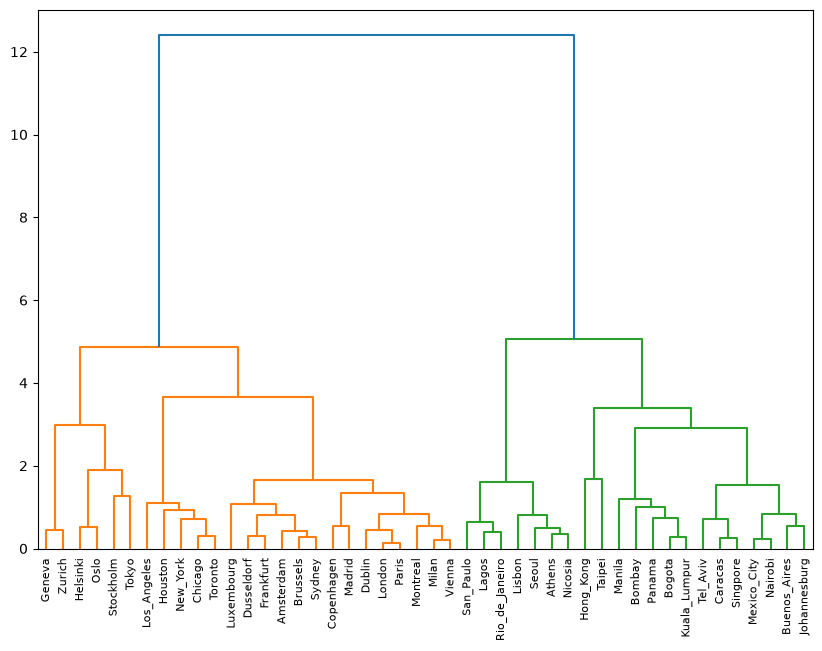

In [271]:
fig = plt.figure(figsize=(10, 7))
dn = dendrogram(link, labels=df["City"].tolist())

Алгоритм покрасил два кластера, и, в принципе, с этим можно согласиться и оставить всего два кластера. Но попробуем поэкспериментировать, задав пороговое значение

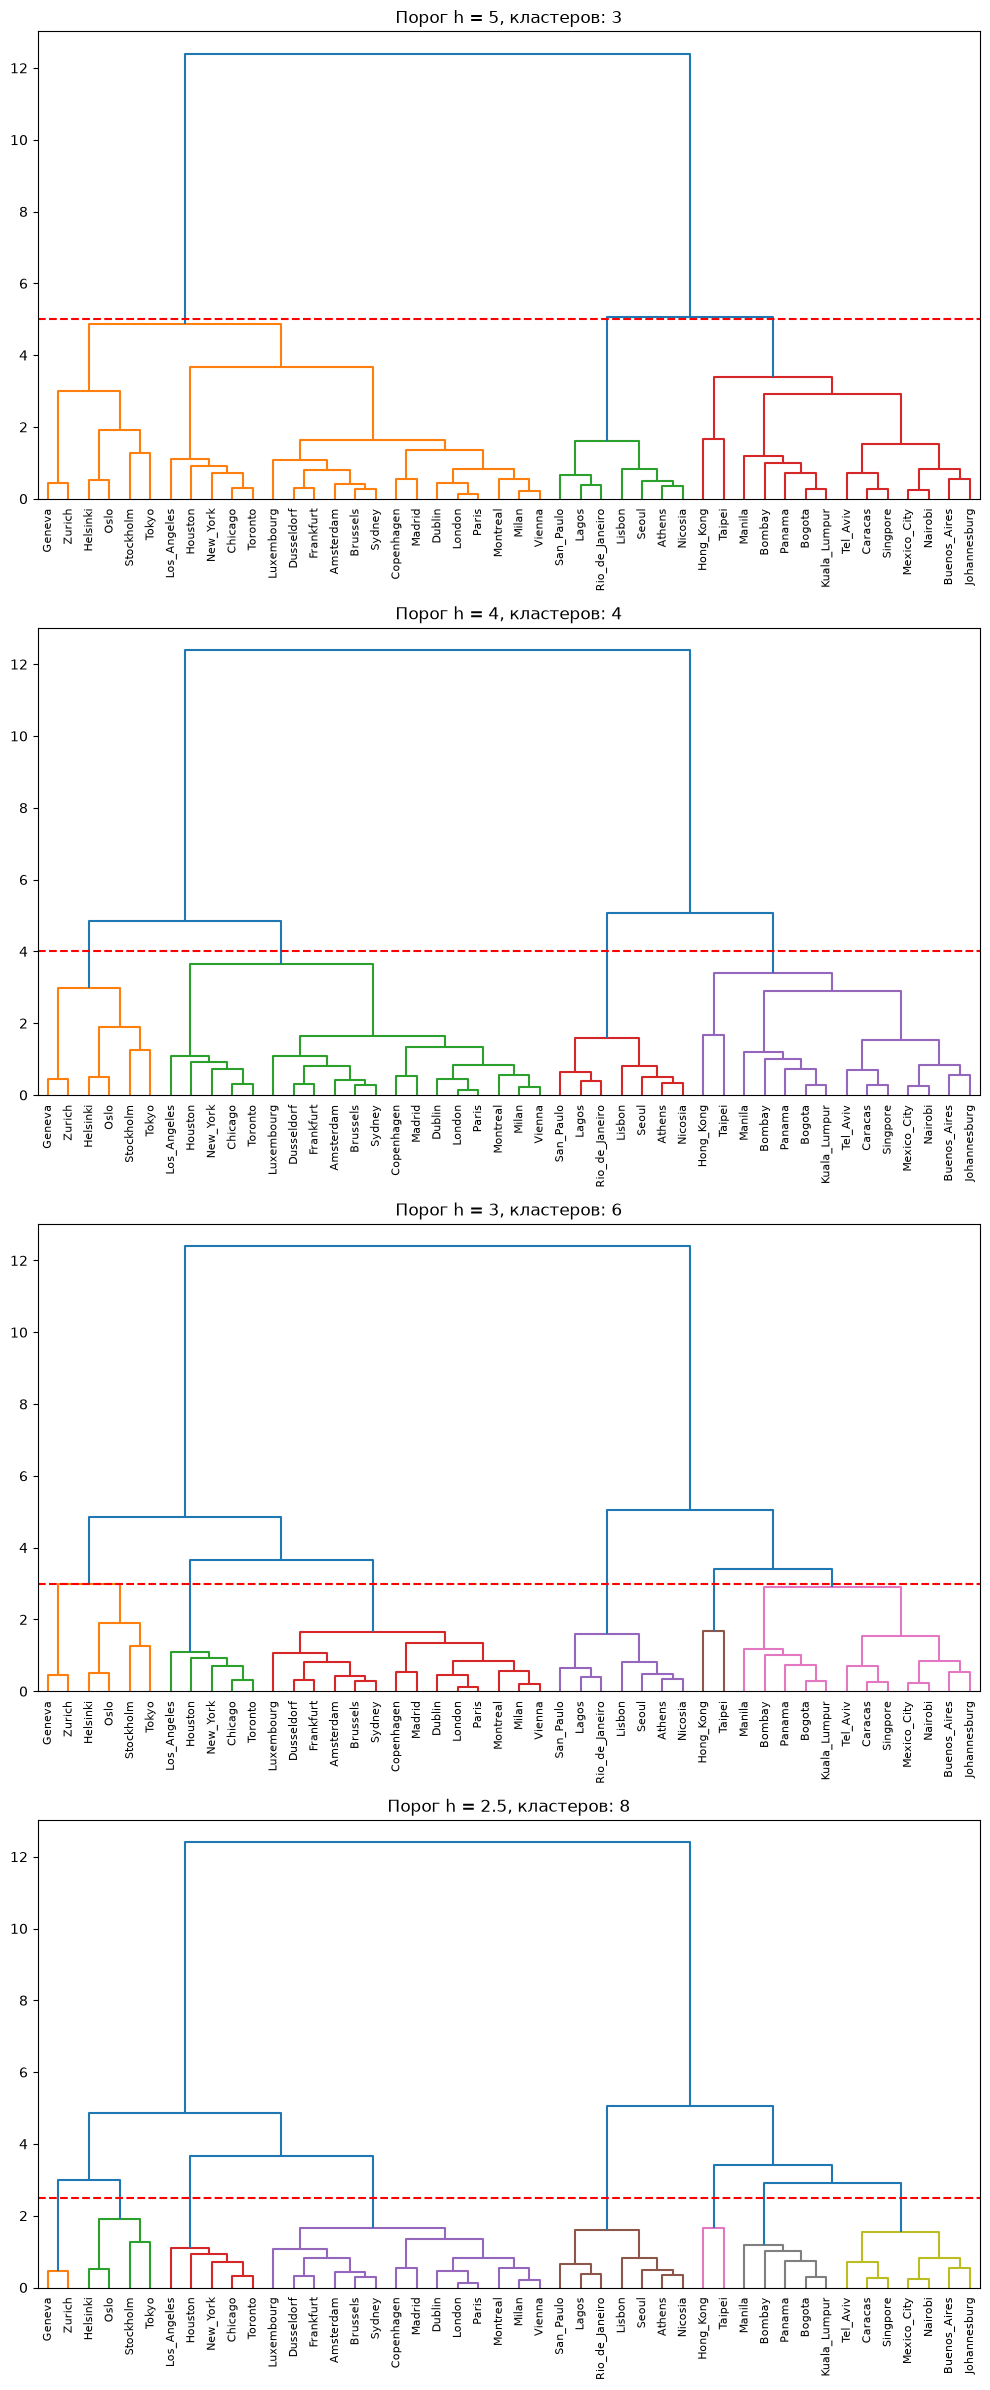

In [272]:
h = [5, 4, 3, 2.5]

fig, axes = plt.subplots(len(h), 1, figsize=(10, 6 * len(h)))

for ax, t in zip(axes, h):
    dendrogram(link, color_threshold=t, labels=df["City"].tolist(), ax=ax)
    ax.axhline(y=t, color="r", linestyle="--")
    n_clusters = len(np.unique(fcluster(link, t=t, criterion="distance")))
    ax.set_title(f"Порог h = {t}, кластеров: {n_clusters}")

plt.tight_layout()
plt.show()


Мне нравятся дендрограммы с 2-мя (порог 6) и с 4-мя (порог 4) кластерами. Возьмем дальше в работу 4 кластера, добавим к таблице данных df столбец `cluster`, содержащий код кластера, в который попал объект

In [273]:
# Останавливаем объединение
df["cluster"] = fcluster(link, 4, criterion="maxclust")

In [274]:
df.head(20)

,City,Work,Price,Salary,cluster
0,Amsterdam,1714,65.6,49.0,2
1,Athens,1792,53.8,30.4,3
2,Bogota,2152,37.9,11.5,4
3,Bombay,2052,30.3,5.3,4
4,Brussels,1708,73.8,50.5,2
5,Buenos_Aires,1971,56.1,12.5,4
6,Caracas,2041,61.0,10.9,4
7,Chicago,1924,73.9,61.9,2
8,Copenhagen,1717,91.3,62.9,2
9,Dublin,1759,76.0,41.4,2


### Интерпретация кластеров

Метод варда позволил нам определить кластеры, значит у нас шаровые скопления, теперь посмотрим на средние признаков в каждом кластере и интерпретируем их

In [275]:
df.groupby("cluster").mean(numeric_only=True).round(3)

,Work,Price,Salary
cluster,,,
1,1780.500,108.550,71.300
2,1792.000,77.526,55.158
3,1798.857,50.943,19.214
4,2082.357,53.121,14.914


Вспомним кратко что означают каждый из признаков:
- Work (Работа): среднее числа рабочих часов
- Price (Цена): Индекс цен 112 товаров и услуг
- Salary (Заработная плата): индекс з/п за час работы.

Отсюда видно следующее:
1. **Очень богатые:** имеют низкое кол-во часов работы, при этом с высокими ценами и высокой зарплатой.
2. **Средние/богатые:** имеют такое же кол-во часов работы, с средними ценами, но также неплохой зарплатой. Можно также назвать средним классом
3. **Бедные (кластеры 3 и 4):** имеют самые низкие цены на товары и услуги, также оплату труда. При этом 4ый кластер больше работает, в отличие от остальных.

Кластеры 1 и 2 можно объединить (порог h = 5), тогда получится три группы: богатые, средние, много работают. А при большом пороге (h=6) останется только две группы: богатые города и все остальные.

Посмотрим на то, какие города относятся к каждому из кластеров

In [276]:
for cluster_id, group in df.groupby("cluster"):
    print(f"\nКластер {cluster_id} (размер {group.shape[0]}):")
    print(group["City"].tolist())


Кластер 1 (размер 6):
['Geneva', 'Helsinki', 'Oslo', 'Stockholm', 'Tokyo', 'Zurich']

Кластер 2 (размер 19):
['Amsterdam', 'Brussels', 'Chicago', 'Copenhagen', 'Dublin', 'Dusseldorf', 'Frankfurt', 'Houston', 'London', 'Los_Angeles', 'Luxembourg', 'Madrid', 'Milan', 'Montreal', 'New_York', 'Paris', 'Sydney', 'Toronto', 'Vienna']

Кластер 3 (размер 7):
['Athens', 'Lagos', 'Lisbon', 'Nicosia', 'Rio_de_Janeiro', 'San_Paulo', 'Seoul']

Кластер 4 (размер 14):
['Bogota', 'Bombay', 'Buenos_Aires', 'Caracas', 'Hong_Kong', 'Johannesburg', 'Kuala_Lumpur', 'Manila', 'Mexico_City', 'Nairobi', 'Panama', 'Singpore', 'Taipei', 'Tel_Aviv']


**Визуализируем кластеры**

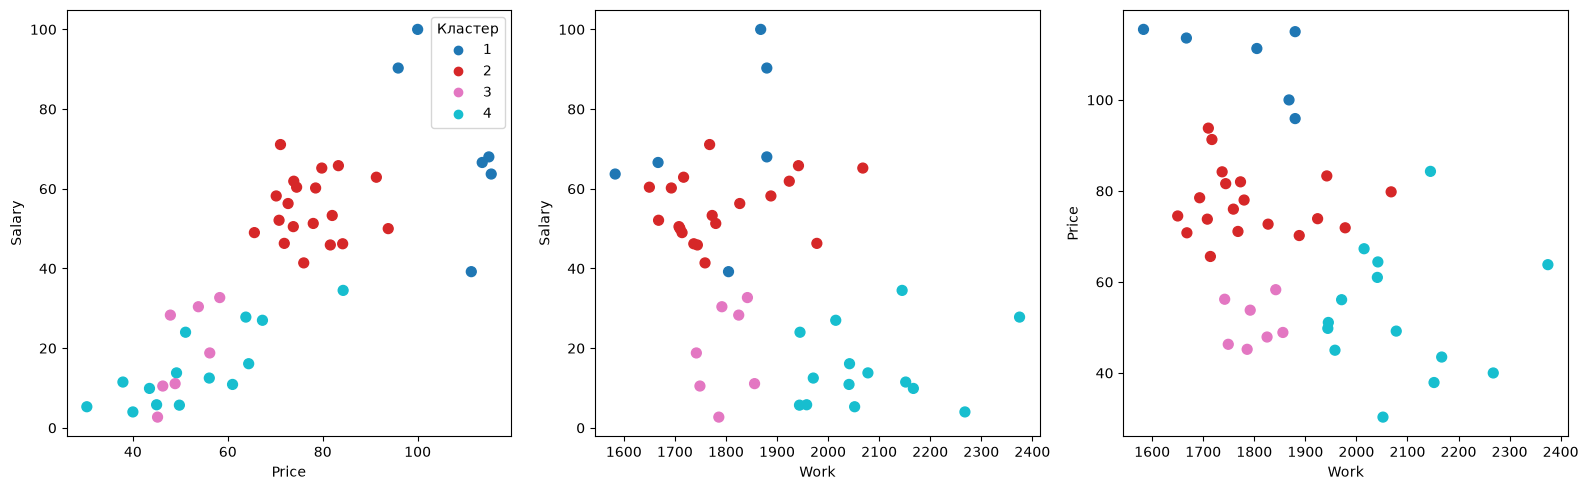

In [281]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (x, y) in zip(axes, [("Price", "Salary"), ("Work", "Salary"), ("Work", "Price")]):
    sc = ax.scatter(df[x], df[y], c=df["cluster"], cmap="tab10", s=50)
    ax.set_xlabel(x); ax.set_ylabel(y)
axes[0].legend(*sc.legend_elements(), title="Кластер")
plt.tight_layout()
plt.show()

### Каменистая осыпь (или же локоть)

Попробуем воспользоваться методом, помогающим определить число кластеров

Text(0, 0.5, 'Расстояние')

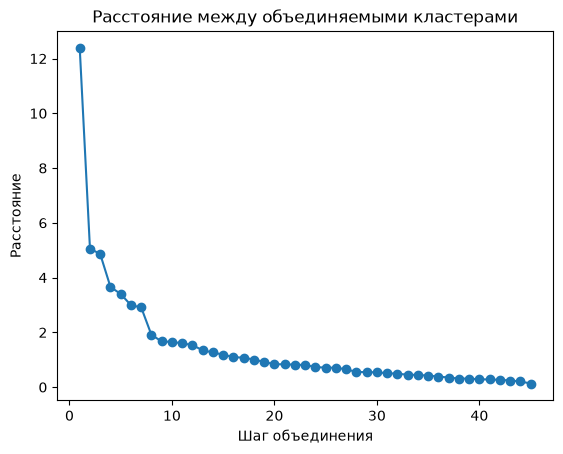

In [278]:
# Расстояния между объединяемыми кластерами
dist = link[:, 2]

# Нарисуем график зависимости расстояния между кластерами от шага объединения
dist_rev = dist[::-1]
idxs = range(1, len(dist) + 1)
plt.plot(idxs, dist_rev, marker='o')
plt.title('Расстояние между объединяемыми кластерами')
plt.xlabel('Шаг объединения')
plt.ylabel('Расстояние')

Из картинки видно, что если мы остановим объединение кластеров при расстоянии равном примерно 4, мы получим 4 кластера, а при равном 2.5 - 8 кластеров. Это мы и определили при эксперименте выше. 

**Также посмотрим на силуэт**

In [279]:
for k in range(2, 9):
    labels = fcluster(link, k, criterion="maxclust")
    print(f"k = {k}: силуэт = {silhouette_score(df_scaled, labels):.3f}")

k = 2: силуэт = 0.470
k = 3: силуэт = 0.361
k = 4: силуэт = 0.355
k = 5: силуэт = 0.348
k = 6: силуэт = 0.366
k = 7: силуэт = 0.396
k = 8: силуэт = 0.399


При k = 2 силуэт выше, но мы выбрали k = 4, поскольку это всего лишь ориентир, а не окончательный критерий, и при k = 4 мы определили и интепретировали больше информации, чем если бы работали лишь с двумя кластерами.

### Проведем сравнения с другими методами

Рассмотрим расстояние между кластерами не выбранным нами ранее `ward`, а `complete`, `average` и `single`

В лекциях этого нет, но при сравнении кластеров  мне понадобилось какой-то метрикой сравнить полученные кластеры, насколько они отличаются от нашего разбиения объектов методом `Ward`, для этого отлично подошла метрика ARI (Adjusted Rand Index, т.н. скорректированный индекс Рэнда). Он показывает, насколько совпадают два разбиения одних и тех же объектов. Выбран он был по тому, что он легко считается одной функцией `adjusted_rand_score` из библиотеки `scikit-learn`. Теперь можно сравнить новые методы с выбранным нами ранее.

In [280]:
labels_ward = df["cluster"]

for method in ["complete", "average", "single"]:
    link_method = linkage(df_scaled, method=method, metric="euclidean")
    labels_method = fcluster(link_method, 4, criterion="maxclust")

    print(f"\n Метод: {method}: ARI c Ward = {adjusted_rand_score(labels_ward, labels_method):.2f}")
    # Выведем средние значения признаков для каждого кластера
    df_method = df.copy()
    df_method["cluster"] = labels_method
    print(df_method.groupby("cluster").mean(numeric_only=True).round(3))



 Метод: complete: ARI c Ward = 0.84
             Work    Price  Salary
cluster                           
1        1792.000   77.526  55.158
2        1780.500  108.550  71.300
3        1855.455   50.782  16.591
4        2133.500   54.170  16.080

 Метод: average: ARI c Ward = 0.76
             Work    Price  Salary
cluster                           
1        1792.000   77.526  55.158
2        1780.500  108.550  71.300
3        2260.000   74.050  31.150
4        1959.211   50.116  14.789

 Метод: single: ARI c Ward = 0.08
             Work    Price  Salary
cluster                           
1        1874.000   97.950   95.15
2        1868.405   67.855   36.50
3        1880.000  115.000   68.00
4        2375.000   63.800   27.80


Отсюда видно следующее:
- **Complete** имеет ARI с Ward'ом равной **0.84**. Это значит что кластеризация у этих двух методов сильно совпадает, также это видно при интерпритации: получились примерно такие же кластеры с небольшими отклонениями (например у третьего кластера зарплата не $19$, а $16.5$).
- У метода **average** метрика ARI с Ward'ом также высокая = **0.76**, 
- А у метода single метрика низкая (**0.08**) - у него совсем другое разбиение и вполне вероятно порог 4 ему уже может не подходить (как и наши данные в принципе, если он ищет ленточные скопления)

**Таким образом разбиение устойчиво!**

## Общий вывод

Мы рассмотрели датасет **Economics of Cities**. За это время мы:
- приняли решение о необходимости стандартизовать данные (привести к единому масштабу)
- обнаружили и избавились от выбросов (значения -9999 в двух признаках `Work` и `Salary`)
- собственно, стандартизовали данные
- выбрали Варда и евклидово расстояния для построения последующих дендрограмм
- провели эксперимент с разным пороговым значением
- добавили новый признак `cluster` к каждому из объектов
- интерпретировали полученные данные
- применили инструмент **каменистая осыпь** для определения количества кластеров.
- провели сравнительный анализ с другими методами

Таким образом, иерархический кластерный анализ дал нам следующие результаты:
1. В данных присутствуют **самые дорогие и высокооплачиваемые города** (Женева, Цюрих, Осло, Стокгольм, Хельсинки, Токио): максимальные цены ($\approx 109$) и зарплаты ($\approx 71$);
2. **Богатые города** (крупные города западной Европы, США, Канады и Сидней): цены и зарплаты высокие, но ниже чем в первом кластере ($\approx 78$ и $\approx 55$ соответственно);
3. **Средний уровень жизни** (Афины, Лиссабон, Никосия, Сеул, Рио-де-Жанейро, Сан-Паулу, Лагос): низкие цены ($\approx 51$) и зарплаты ($\approx 19$) при обычной продолжительности рабочего времени;
4. **Много работают за низкую оплату труда** (Латинская Америка, Южная и Юго-Восточная Азия, Африка): цены и зарплаты близки к третьему кластеру, но рабочих часов почти на 300 больше ($\approx 2080$).

Первый и второй кластеры отличаются разницей в цене и зарплате, второй и третий - отличаются также ценой и зарплатой, третий и четвертый - средним временем рабочих часов. Объединять их между собой можно на свой вкус и цвет (оставить 2-3 или разбить на большее количество кластеров, например)

**Итог: кластерный анализ удался!**